# ECG exploratory data analysis

Load an unmodified MIT-BIH Arrhythmia Database signal and its `.atr` annotations. Dataset provenance and license: [DATA_NOTICE.md](../DATA_NOTICE.md). Record 100 is the example used in the starter notebook; set `record_id` to another ID from `data/RECORDS` to inspect it.

In [ ]:
from collections.abc import Sequence
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import wfdb

project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").exists() and (path / "data/RECORDS").exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Open the notebook inside the project folder.")

record_id = "100"
record_ids = (project_root / "data/RECORDS").read_text().splitlines()
if record_id not in record_ids:
    raise ValueError(f"Unknown record ID: {record_id}")
record_path = project_root / "data/raw/mitdb-1.0.0" / record_id
record = wfdb.rdrecord(str(record_path))
annotations = wfdb.rdann(str(record_path), "atr")

if not isinstance(record, wfdb.Record):
    raise TypeError("Expected a single-segment WFDB Record.")

print(f"Record: {record.record_name}")
print(f"Samples: {record.sig_len}, sampling rate: {record.fs} Hz")
print(f"Channels: {list(zip(record.sig_name, record.units))}")
print(f"Annotations: {len(annotations.sample)}")

Record: 100
Samples: 650000, sampling rate: 360 Hz
Channels: [('MLII', 'mV'), ('V5', 'mV')]
Annotations: 2274


In [ ]:
from collections import Counter

Counter(annotations.symbol)

Counter({'N': 2239, 'A': 33, '+': 1, 'V': 1})

## Signal with annotations

The plot uses physical signal values and sample positions from the raw files. Every `.atr` annotation in the selected time interval is marked at its sample position and labeled with its original WFDB symbol. No annotation symbols are remapped or excluded. The displayed interval is half-open: `[start_s, start_s + duration_s)`.

Select a single channel with `channel=0` or both channels with `channel=(0, 1)`. Set `layout="overlay"` for one shared axis or `layout="stacked"` for separate rows with a shared time axis. Each channel's signal, annotation markers, and symbols share a color. Both examples below use the same 10-second interval.

In [ ]:
def plot_ecg_with_annotations(
    record,
    annotations,
    channel: int | Sequence[int] = 0,
    start_s=0.0,
    duration_s=10.0,
    layout="overlay",
):
    """Plot one or two ECG channels with their original `.atr` annotation symbols.

    The displayed interval is [start_s, start_s + duration_s). Each annotation
    is placed at its sample position on every selected channel, with its symbol
    to the right of the marker. A channel's signal, annotation markers, and
    annotation symbols share the same color.

    Args:
        record: WFDB Record with loaded physical signal values.
        annotations: WFDB Annotation for the same record.
        channel: Zero-based channel index or a sequence of one or two unique
            indices, such as (0, 1). Defaults to 0.
        start_s: Interval start in seconds (default: 0).
        duration_s: Interval length in seconds (default: 10).
        layout: "overlay" draws selected channels on one axis; "stacked" draws
            one channel per row with a shared time axis. Defaults to "overlay".
            Overlay requires all selected channels to use the same unit.

    Returns:
        Tuple of a Matplotlib figure and either one Axes object or an array of
        Axes objects when multiple channels are stacked.
    """
    if record.record_name != annotations.record_name:
        raise ValueError("The signal and annotations must belong to the same record.")
    if annotations.fs is not None and annotations.fs != record.fs:
        raise ValueError("The signal and annotation sampling rates differ.")
    if isinstance(channel, (int, np.integer)):
        channels = [channel]
    else:
        try:
            channels = list(channel)
        except TypeError as exc:
            raise ValueError("Channel must be an index or a sequence of indices.") from exc
    if not 1 <= len(channels) <= 2 or any(
        not isinstance(index, (int, np.integer)) or not 0 <= index < record.n_sig
        for index in channels
    ):
        raise ValueError(f"Select one or two channel indices from 0 to {record.n_sig - 1}.")
    if len(set(channels)) != len(channels):
        raise ValueError("Channel indices must be unique.")
    if layout not in ("overlay", "stacked"):
        raise ValueError('Layout must be "overlay" or "stacked".')
    if layout == "overlay" and len({record.units[index] for index in channels}) != 1:
        raise ValueError("Overlay requires matching channel units; use the stacked layout.")
    if not np.isfinite(start_s) or not np.isfinite(duration_s) or start_s < 0 or duration_s <= 0:
        raise ValueError("Use a nonnegative start and a positive, finite duration.")

    first = round(start_s * record.fs)
    last = round((start_s + duration_s) * record.fs)
    if first >= last or last > record.sig_len:
        raise ValueError(f"The interval must contain samples within 0–{record.sig_len / record.fs:.2f} s.")

    sample_indices = np.arange(first, last)
    annotation_mask = (annotations.sample >= first) & (annotations.sample < last)
    annotation_samples = annotations.sample[annotation_mask]
    annotation_symbols = np.asarray(annotations.symbol)[annotation_mask]

    rows = len(channels) if layout == "stacked" else 1
    fig, axes = plt.subplots(nrows=rows, sharex=True, figsize=(14, 4 * rows))
    plot_axes = np.atleast_1d(axes)
    for position, index in enumerate(channels):
        ax = plot_axes[position if layout == "stacked" else 0]
        signal = record.p_signal[:, index]
        line, = ax.plot(
            sample_indices / record.fs, signal[first:last], linewidth=0.8,
            color=f"C{position}", label=record.sig_name[index],
        )
        ax.scatter(
            annotation_samples / record.fs, signal[annotation_samples],
            color=line.get_color(), s=24, zorder=3,
        )
        for sample, symbol in zip(annotation_samples, annotation_symbols):
            ax.annotate(
                symbol, (sample / record.fs, signal[sample]),
                xytext=(7, 0), textcoords="offset points",
                ha="left", va="center", color=line.get_color(), fontsize=8,
                bbox=dict(facecolor="white", edgecolor="none", pad=0.2),
            )

    for position, ax in enumerate(plot_axes):
        axis_channels = [channels[position]] if layout == "stacked" else channels
        names = ", ".join(record.sig_name[index] for index in axis_channels)
        ax.set(ylabel=f"Amplitude ({record.units[axis_channels[0]]})",
               title=f"Record {record.record_name}: {names}")
        ax.set_xlim(first / record.fs, last / record.fs)
        ax.margins(y=0.2)
        ax.grid(alpha=0.25)
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    plot_axes[-1].set_xlabel("Time (s)")
    fig.tight_layout()
    return fig, axes

### Example 1: both channels on one axis

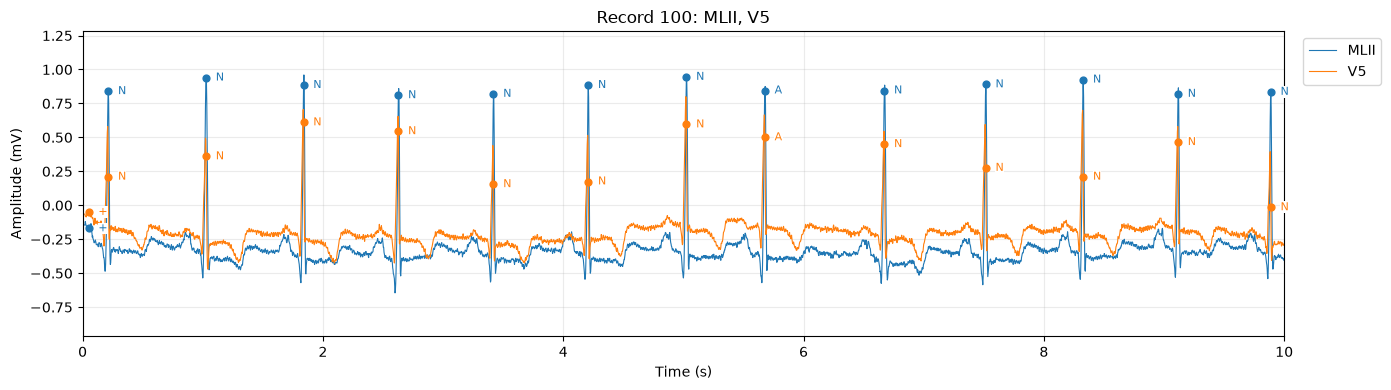

In [ ]:
fig, ax = plot_ecg_with_annotations(
    record, annotations, channel=(0, 1), start_s=0, duration_s=10, layout="overlay"
)
plt.show()

### Example 2: one channel per row

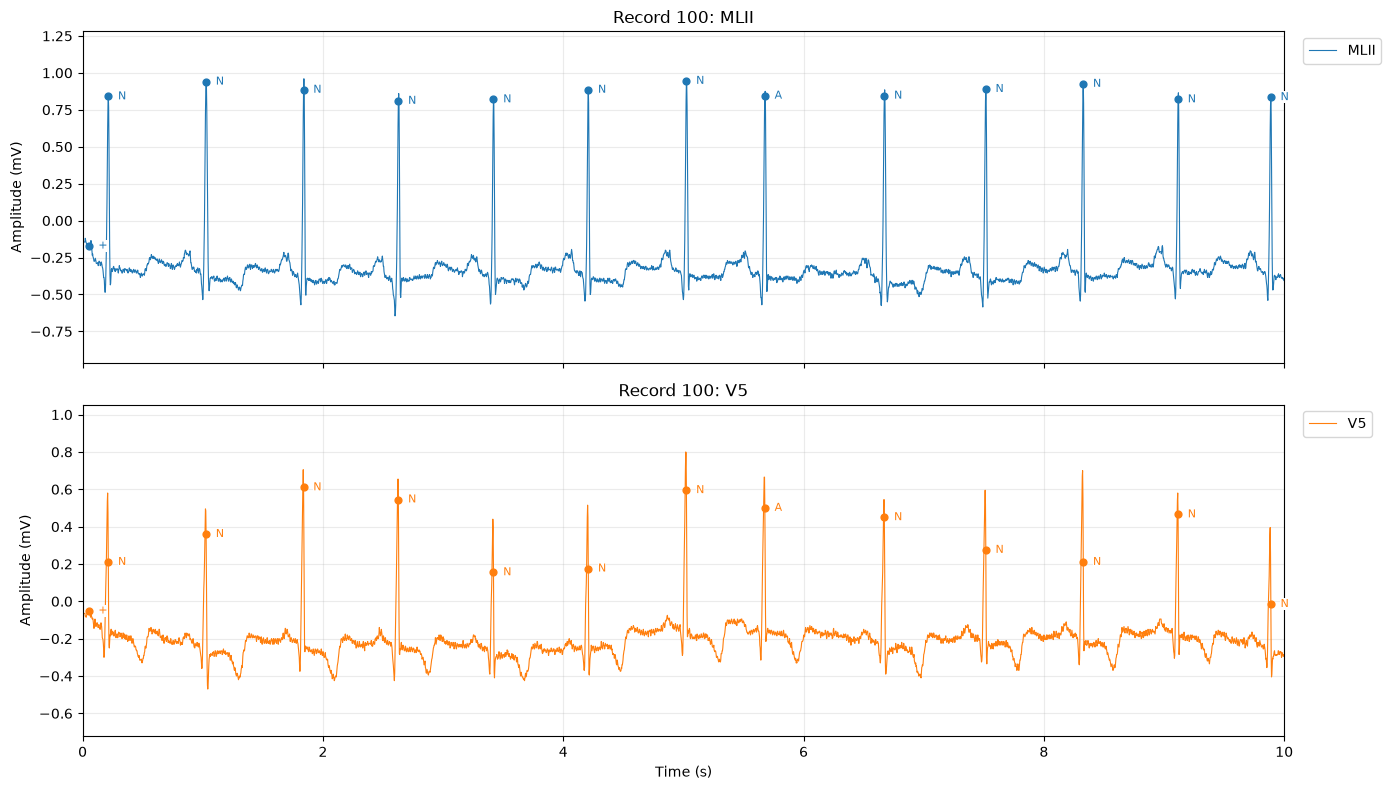

In [ ]:
fig, axes = plot_ecg_with_annotations(
    record, annotations, channel=(0, 1), start_s=0, duration_s=10, layout="stacked"
)
plt.show()

## Annotation-centered windows

Each `ECGWindow` contains one selected channel from −0.5 s to +0.5 s, including both endpoints. At 360 Hz this gives 361 samples, with the central annotation at index 180. Missing samples are replaced by zeros; `left_padding` and `right_padding` record their counts, and `is_complete` is false if either count is nonzero.

`annotation` identifies the center. `other_annotations` contains every other `.atr` entry in the interval except `+`, including entries with the same symbol and entries at either endpoint. The `+` marker is excluded both as a central annotation and among other annotations. Each retained entry keeps its original annotation index, absolute sample, symbol, auxiliary note, and signed `offset_samples` from the center. Divide the offset by `fs` for seconds.

`extract_ecg_window` selects the center by its index in the annotation set. `generate_ecg_windows` yields windows lazily for an exact symbol (default `N`) and one channel (default `0`). Use full recordings and annotations with the same sample origin.

Extraction can retain zero-padded candidates for inspection and rejection accounting; final datasets below contain complete windows only.

In [1]:
from collections.abc import Iterator
from dataclasses import dataclass, field

import numpy as np
import wfdb


@dataclass(frozen=True)
class WindowAnnotation:
    """An annotation located relative to a window's central annotation.

    Attributes:
        annotation_index: Index of this entry in the original annotation set.
        sample: Absolute sample index in the source record.
        symbol: Original WFDB annotation symbol.
        offset_samples: Signed sample offset from the central annotation.
        aux_note: Original auxiliary note, if available.
    """

    annotation_index: int
    sample: int
    symbol: str
    offset_samples: int
    aux_note: str | None = None


@dataclass
class ECGWindow:
    """One channel spanning 0.5 seconds on either side of an annotation.

    Both endpoints are included: at 360 Hz, signal has 361 samples and its
    central annotation is at index 180. Missing source samples are zeros.

    Attributes:
        signal: Independent 1D array of physical signal values, including padding.
        fs: Sampling rate in Hz.
        record_name: Identifier of the source recording.
        channel: Zero-based channel index in the source record.
        channel_name: Original channel name.
        unit: Physical unit of the signal values, for example mV.
        annotation: Central annotation; its offset_samples is always zero.
        other_annotations: All other entries except + in the inclusive window interval,
            including entries with the same symbol or at the same sample.
        left_padding: Number of missing samples replaced by zeros on the left.
        right_padding: Number of missing samples replaced by zeros on the right.
    """

    signal: np.ndarray = field(repr=False)
    fs: float
    record_name: str
    channel: int
    channel_name: str
    unit: str
    annotation: WindowAnnotation
    other_annotations: tuple[WindowAnnotation, ...]
    left_padding: int
    right_padding: int

    @property
    def center_index(self) -> int:
        """Return the central annotation's sample index within signal."""
        return self.signal.size // 2

    @property
    def is_complete(self) -> bool:
        """Return True if every sample comes from the source, without padding."""
        return self.left_padding == 0 and self.right_padding == 0

    @property
    def has_other_annotations(self) -> bool:
        """Return True if another annotation with a symbol other than + is present."""
        return bool(self.other_annotations)

In [12]:
def extract_ecg_window(
    record: wfdb.Record,
    annotations: wfdb.Annotation,
    annotation_index: int,
    channel: int = 0,
) -> ECGWindow:
    """Extract a centered, single-channel window, padding missing samples with zeros.

    The inclusive interval is [annotation time - 0.5 s, annotation time + 0.5 s].
    The sampling rate must place both endpoints on integer sample indices.
    Annotation entries are distinguished by their original indices, so another
    entry at the central sample is retained among other_annotations, unless
    its symbol is +. The + marker is never a valid window center.

    Args:
        record: WFDB Record with physical signals loaded from sample zero.
        annotations: WFDB Annotation using the same record and sample origin.
        annotation_index: Zero-based index of the central annotation entry,
            not its sample position in the recording.
        channel: Zero-based channel to extract (default: 0).

    Returns:
        ECGWindow with a signal copy, original annotation metadata, and padding
        counts. Its is_complete flag is False whenever padding was needed.
    """
    signal = record.p_signal
    samples = annotations.sample
    symbols = annotations.symbol
    names = record.sig_name
    units = record.units
    fs = record.fs
    if signal is None or samples is None or symbols is None:
        raise ValueError("Physical signal values, annotation samples, and symbols are required.")
    if names is None or units is None or record.record_name is None:
        raise ValueError("Record name, channel names, and physical units are required.")
    if record.record_name != annotations.record_name:
        raise ValueError("The signal and annotations must belong to the same record.")
    if fs is None or not np.isfinite(fs) or fs <= 0:
        raise ValueError("The record must have a positive, finite sampling rate.")
    if annotations.fs is not None and annotations.fs != fs:
        raise ValueError("The signal and annotation sampling rates differ.")
    half_width = float(fs) * 0.5
    if not half_width.is_integer():
        raise ValueError("The sampling rate must represent 0.5 seconds as an integer sample count.")
    if signal.ndim != 2 or signal.shape[0] == 0:
        raise ValueError("Physical signals must be a nonempty samples-by-channels array.")
    if not isinstance(channel, (int, np.integer)) or not 0 <= channel < signal.shape[1]:
        raise ValueError(f"Channel must be an integer from 0 to {signal.shape[1] - 1}.")
    if len(names) != signal.shape[1] or len(units) != signal.shape[1]:
        raise ValueError("Channel metadata must match the signal columns.")
    if samples.ndim != 1 or not np.issubdtype(samples.dtype, np.integer) or len(samples) != len(symbols):
        raise ValueError("Annotation samples must be a 1D integer array matching the symbols.")
    if np.any(samples < 0) or np.any(samples >= signal.shape[0]):
        raise ValueError("Annotation samples must lie within the source recording.")
    if not isinstance(annotation_index, (int, np.integer)) or not 0 <= annotation_index < len(samples):
        raise ValueError("Annotation index must identify an entry in the annotation set.")
    if symbols[annotation_index] == "+":
        raise ValueError("The + marker cannot be a window center.")
    notes = annotations.aux_note
    if notes is not None and len(notes) != len(samples):
        raise ValueError("Auxiliary notes must match the annotation entries.")

    half_samples = int(half_width)
    center = int(samples[annotation_index])
    first = center - half_samples
    last = center + half_samples + 1
    left_padding = max(0, -first)
    right_padding = max(0, last - signal.shape[0])
    window_signal = np.zeros(2 * half_samples + 1, dtype=signal.dtype)
    window_signal[left_padding:window_signal.size - right_padding] = signal[
        max(0, first):min(signal.shape[0], last), channel
    ]

    inside = np.flatnonzero((samples >= first) & (samples < last))
    entries = tuple(
        WindowAnnotation(
            annotation_index=int(index),
            sample=int(samples[index]),
            symbol=symbols[index],
            offset_samples=int(samples[index]) - center,
            aux_note=notes[index] if notes is not None else None,
        )
        for index in inside
    )
    return ECGWindow(
        signal=window_signal,
        fs=float(fs),
        record_name=record.record_name,
        channel=int(channel),
        channel_name=names[channel],
        unit=units[channel],
        annotation=next(entry for entry in entries if entry.annotation_index == annotation_index),
        other_annotations=tuple(
            entry for entry in entries
            if entry.annotation_index != annotation_index and entry.symbol != "+"
        ),
        left_padding=left_padding,
        right_padding=right_padding,
    )

In [13]:
def generate_ecg_windows(
    record: wfdb.Record,
    annotations: wfdb.Annotation,
    annotation_symbol: str = "N",
    channel: int = 0,
) -> Iterator[ECGWindow]:
    """Yield one window per matching annotation, in the original annotation order.

    Windows are created lazily. Only the center is selected by symbol; all
    other annotation entries inside each window are preserved except +.
    The + marker cannot be selected as a window center.

    Args:
        record: WFDB Record with physical signals loaded from sample zero.
        annotations: WFDB Annotation using the same record and sample origin.
        annotation_symbol: Exact WFDB symbol to use as a window center
            (default: "N"). No label mapping is applied.
        channel: Zero-based channel to extract for every window (default: 0).

    Yields:
        ECGWindow with both 0.5-second endpoints included, original metadata,
        and completeness and other-annotation flags.
    """
    if annotations.symbol is None:
        raise ValueError("Annotation symbols are required.")
    if not isinstance(annotation_symbol, str) or not annotation_symbol:
        raise ValueError("Select a nonempty annotation symbol.")
    if annotation_symbol == "+":
        raise ValueError("The + marker cannot be a window center.")
    for index, symbol in enumerate(annotations.symbol):
        if symbol == annotation_symbol:
            yield extract_ecg_window(record, annotations, annotation_index=index, channel=channel)

In [4]:
windows = list(generate_ecg_windows(record, annotations, channel=0))
print(f"N windows: {len(windows)}")
print(f"Complete: {sum(window.is_complete for window in windows)}")
print(f"Incomplete: {sum(not window.is_complete for window in windows)}")

first_window = windows[0]
print(f"Signal shape: {first_window.signal.shape}; center index: {first_window.center_index}")
print(f"Central annotation: {first_window.annotation}")
print(f"Complete: {first_window.is_complete}; "
      f"padding (left, right): {(first_window.left_padding, first_window.right_padding)}")
print(f"Other annotations present: {first_window.has_other_annotations}")
print(f"Other annotations: {first_window.other_annotations}")

N windows: 2239
Complete: 2237
Incomplete: 2
Signal shape: (361,); center index: 180
Central annotation: WindowAnnotation(annotation_index=1, sample=77, symbol='N', offset_samples=0, aux_note='')
Complete: False; padding (left, right): (103, 0)
Other annotations present: False
Other annotations: ()


## Static window grid

`plot_ecg_windows_grid` plots exactly the list of windows supplied to it as one static Matplotlib figure. Select a manageable subset before calling it; the example below displays the first 20 `N` windows from record 100, channel 0, in four columns.

Time is relative to the central annotation at 0 seconds. All supplied windows share amplitude limits. Red markers identify central annotations; orange markers identify other annotations. Gray regions and `[padded]` titles identify zero padding.

In [ ]:
from collections.abc import Sequence

from matplotlib.lines import Line2D
from matplotlib.patches import Patch


def plot_ecg_windows_grid(
    windows: Sequence[ECGWindow],
    ncols: int = 4,
):
    """Plot the supplied ECG windows as one static grid.

    Time is relative to each central annotation, marked in red at 0 s.
    Other annotations are orange, and symbols appear to the right of markers.
    Gray shading identifies zero padding. Amplitude limits are shared across
    the supplied windows, which must all use the same physical unit.

    Args:
        windows: Nonempty list or sequence of ECGWindow objects in display
            order. Every supplied window is plotted; pass a small selection,
            such as windows[:20], to keep the figure readable.
        ncols: Maximum number of grid columns (default: 4).

    Returns:
        Tuple containing a Matplotlib figure and a 2D array of axes. Unused
        panels in the last row are hidden. Call plt.show() to display it.
    """
    if not len(windows):
        raise ValueError("Provide at least one ECG window.")
    if not isinstance(ncols, int) or ncols <= 0:
        raise ValueError("Column count must be a positive integer.")
    if len({window.unit for window in windows}) != 1:
        raise ValueError("Windows must use the same physical unit for shared amplitude limits.")

    columns = min(ncols, len(windows))
    rows = (len(windows) + columns - 1) // columns
    amplitude_min = min(float(window.signal.min()) for window in windows)
    amplitude_max = max(float(window.signal.max()) for window in windows)
    margin = 0.08 * (amplitude_max - amplitude_min) or 0.1
    fig, axes = plt.subplots(
        rows, columns, squeeze=False, sharex=True, sharey=True,
        figsize=(4 * columns, 2.6 * rows),
    )
    for position, window in enumerate(windows):
        ax = axes.flat[position]
        time_s = (np.arange(window.signal.size) - window.center_index) / window.fs
        if window.left_padding:
            edge = time_s[window.left_padding] - 0.5 / window.fs
            ax.axvspan(time_s[0], edge, facecolor="0.9", zorder=0)
        if window.right_padding:
            edge = time_s[window.signal.size - window.right_padding] - 0.5 / window.fs
            ax.axvspan(edge, time_s[-1], facecolor="0.9", zorder=0)
        ax.plot(time_s, window.signal, color="tab:blue", linewidth=0.8)
        ax.axvline(0, color="0.6", linestyle="--", linewidth=0.6, zorder=0)
        for entry in (window.annotation, *window.other_annotations):
            index = window.center_index + entry.offset_samples
            color = "tab:red" if entry.annotation_index == window.annotation.annotation_index else "tab:orange"
            ax.scatter(time_s[index], window.signal[index], color=color, s=15, zorder=3)
            ax.annotate(
                entry.symbol, (time_s[index], window.signal[index]),
                xytext=(5, 0), textcoords="offset points", ha="left", va="center",
                color=color, fontsize=7,
                bbox=dict(facecolor="white", edgecolor="none", pad=0.2),
            )
        status = " [padded]" if not window.is_complete else ""
        ax.set_title(
            f"#{position + 1} | {window.record_name}:{window.channel_name} | "
            f"{window.annotation.symbol} @ {window.annotation.sample / window.fs:.3f}s{status}",
            fontsize=8,
        )
        ax.set_xlim(time_s[0], time_s[-1])
        ax.set_ylim(amplitude_min - margin, amplitude_max + margin)
        ax.set_xticks([-0.5, 0, 0.5])
        ax.set_xlabel("Time from center (s)", fontsize=8)
        if position % columns == 0:
            ax.set_ylabel(f"Amplitude ({window.unit})", fontsize=8)
        ax.tick_params(labelsize=7, labelbottom=True)
        ax.grid(alpha=0.2)
    for ax in list(axes.flat)[len(windows):]:
        ax.set_axis_off()
    fig.suptitle(f"ECG windows | {len(windows)} selected", fontsize=12)
    fig.legend(
        handles=[
            Line2D([], [], marker="o", linestyle="none", color="tab:red", label="Central annotation"),
            Line2D([], [], marker="o", linestyle="none", color="tab:orange", label="Other annotations"),
            Patch(facecolor="0.9", label="Zero padding"),
        ],
        loc="lower center", ncol=3, fontsize=9,
    )
    fig.tight_layout(rect=(0, 0.035, 1, 0.965))
    return fig, axes

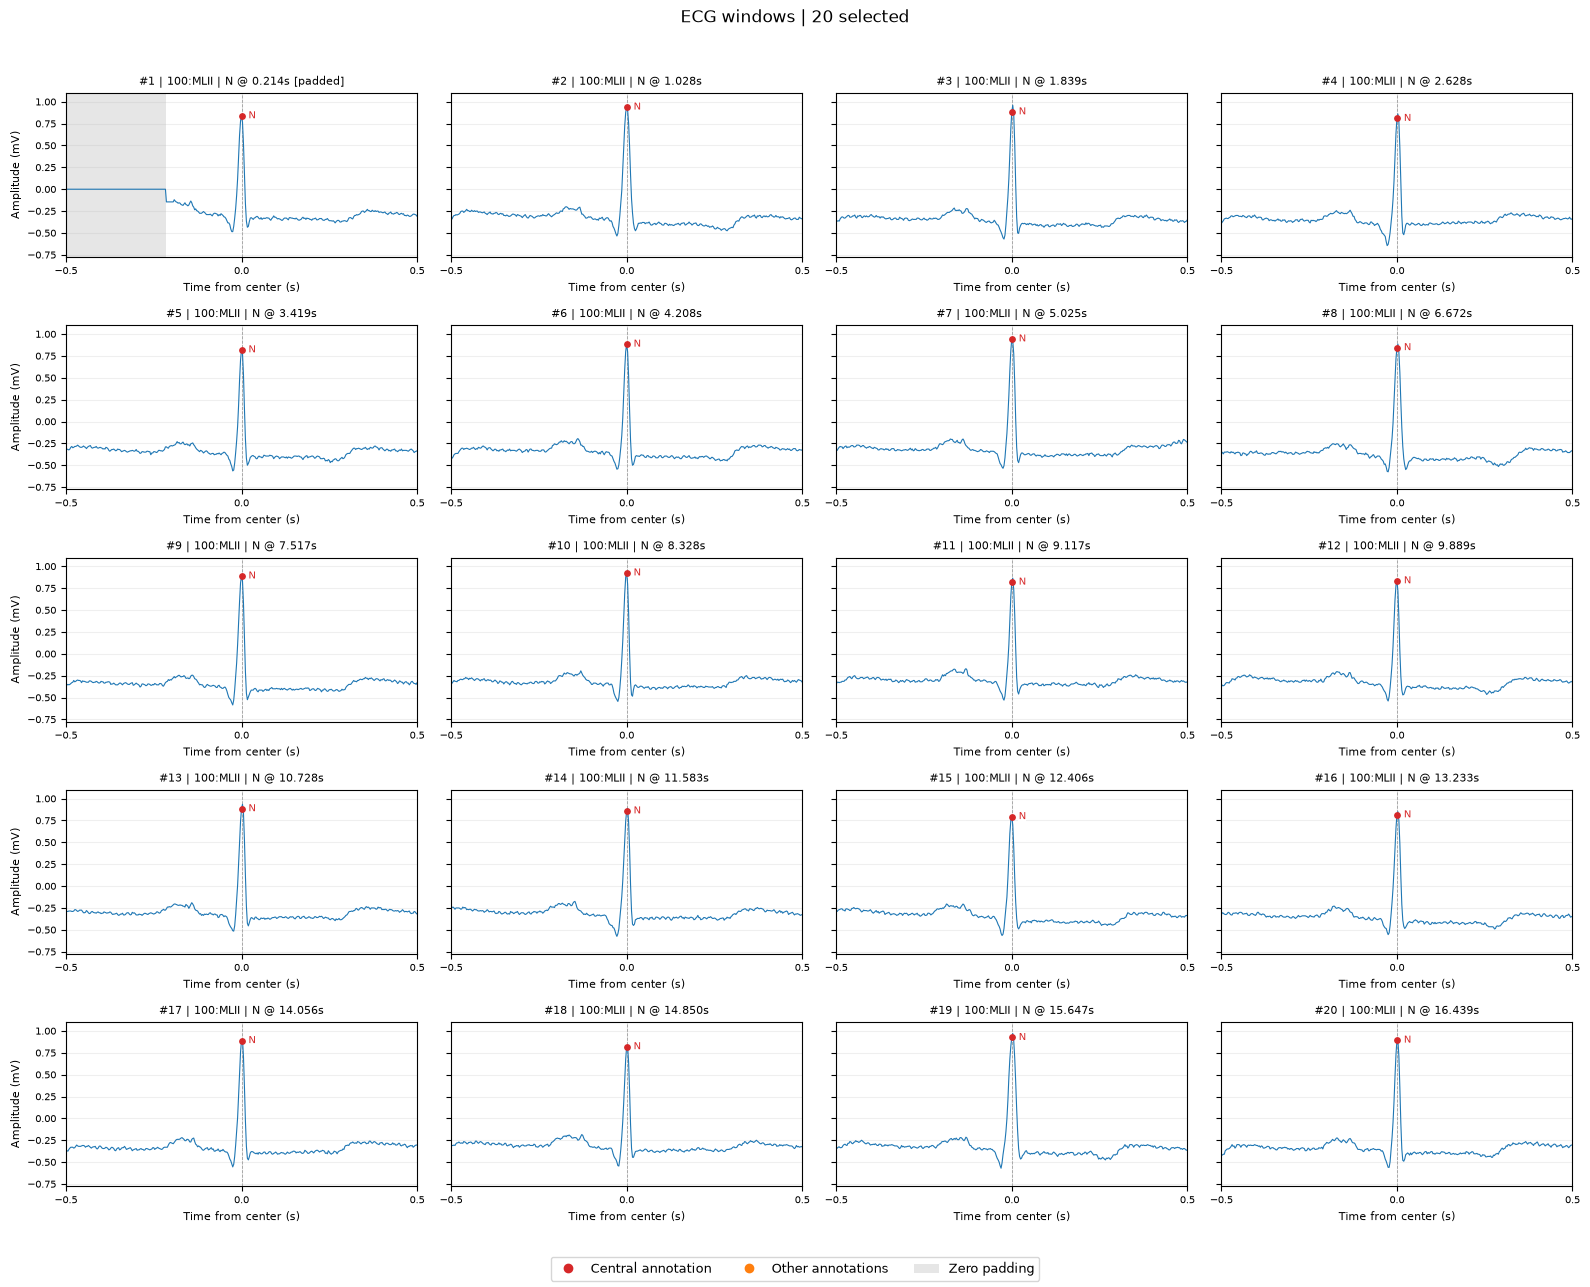

In [5]:
fig, axes = plot_ecg_windows_grid(windows[:20], ncols=4)
plt.show()

## N-window summary across all records

Count all windows centered on `N` annotations from all 48 local records, using channel 0. A **clean** window is complete and has no other retained annotations. Neighboring `+` entries are ignored; other entries, including additional `N` annotations, are counted.

**Incomplete** and **With other annotations** are independent counts and may overlap. **Incomplete with other annotations** reports that overlap. Thus total = clean + incomplete + with other annotations − overlap. `window_summary_by_record` retains the counts for each record; the table below shows the totals. The example record and its `windows` list remain available for the plots above.

These are candidate-window counts before the final complete-window selection below.

In [6]:
import pandas as pd
from IPython.display import display

summary_rows = []
for summary_record_id in record_ids:
    summary_path = project_root / "data/raw/mitdb-1.0.0" / summary_record_id
    summary_record = wfdb.rdrecord(str(summary_path))
    summary_annotations = wfdb.rdann(str(summary_path), "atr")
    counts = {
        "Total N windows": 0,
        "Clean (complete, no other annotations)": 0,
        "Incomplete": 0,
        "With other annotations": 0,
        "Incomplete with other annotations": 0,
    }
    for summary_window in generate_ecg_windows(
        summary_record, summary_annotations, annotation_symbol="N", channel=0
    ):
        counts["Total N windows"] += 1
        counts["Clean (complete, no other annotations)"] += int(
            summary_window.is_complete and not summary_window.has_other_annotations
        )
        counts["Incomplete"] += int(not summary_window.is_complete)
        counts["With other annotations"] += int(summary_window.has_other_annotations)
        counts["Incomplete with other annotations"] += int(
            not summary_window.is_complete and summary_window.has_other_annotations
        )
    summary_rows.append({"Record": summary_record_id, **counts})

window_summary_by_record = pd.DataFrame(summary_rows).set_index("Record")
window_summary = window_summary_by_record.sum().rename("Windows").to_frame()
display(window_summary)

,Windows
Total N windows,75052
"Clean (complete, no other annotations)",68756
Incomplete,41
With other annotations,6257
Incomplete with other annotations,2


## Subject split and leakage check

`data/record_splits.csv` assigns all 48 records to **29 training, 9 validation, and 9 test subjects**. Record 100 is fixed in training. `subject_id` is a project grouping key, normally equal to `record_id`; records 201 and 202 both use subject 201. It is not an external patient identifier.

The remaining 46 subject IDs are sorted, permuted with `numpy.random.default_rng(42)`, and assigned 28/9/9 to train/validation/test. All records of a subject inherit the same assignment. Reproduce the CSV with `uv run --locked python scripts/create_splits.py`. The script preserves any differing existing CSV.

The check below validates record coverage, the known 201/202 relationship, subject isolation, counts, and the fixed assignment of record 100. Run the tests with `uv run --locked python -m unittest discover -s tests -v`.

In [7]:
import sys

import pandas as pd
from IPython.display import display

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from scripts.create_splits import validate_record_splits

record_splits = pd.read_csv(project_root / "data/record_splits.csv", dtype=str)
validate_record_splits(record_splits, record_ids)
split_order = ["train", "validation", "test"]
split_sizes = record_splits.groupby("split").agg(
    Subjects=("subject_id", "nunique"), Records=("record_id", "size")
).reindex(split_order)
print("Subject isolation check passed: every subject belongs to exactly one split.")
display(split_sizes)

Subject isolation check passed: every subject belongs to exactly one split.


,Subjects,Records
split,,
train,29,30
validation,9,9
test,9,9


## Window comparison by split and central symbol

Count channel-0 windows for **every original central annotation symbol except `+`**, without mapping labels. These are candidate-window counts before the final complete-window selection below. All windows inherit the split of their source record. The first table compares split totals, the second compares central symbols, and the last gives quality counts for each symbol in each split. Missing symbol/split combinations are shown as zero.

**Clean** means complete with no other retained annotations. Neighboring `+` entries are ignored, while other neighboring entries, including the same symbol as the center, are counted. **Incomplete** and **With other annotations** may overlap; their intersection is reported separately. For every row, total = clean + incomplete + with other annotations − overlap.

In [14]:
split_count_rows = []
for split_assignment in record_splits.itertuples(index=False):
    split_record_path = project_root / "data/raw/mitdb-1.0.0" / split_assignment.record_id
    split_record = wfdb.rdrecord(str(split_record_path))
    split_annotations = wfdb.rdann(str(split_record_path), "atr")
    for center_symbol in sorted(set(split_annotations.symbol) - {"+"}):
        split_counts = {
            "Total": 0,
            "Clean": 0,
            "Incomplete": 0,
            "With other annotations": 0,
            "Incomplete with other annotations": 0,
        }
        for split_window in generate_ecg_windows(
            split_record, split_annotations, annotation_symbol=center_symbol, channel=0
        ):
            split_counts["Total"] += 1
            split_counts["Clean"] += int(split_window.is_complete and not split_window.has_other_annotations)
            split_counts["Incomplete"] += int(not split_window.is_complete)
            split_counts["With other annotations"] += int(split_window.has_other_annotations)
            split_counts["Incomplete with other annotations"] += int(
                not split_window.is_complete and split_window.has_other_annotations
            )
        split_count_rows.append({
            "record_id": split_assignment.record_id,
            "subject_id": split_assignment.subject_id,
            "split": split_assignment.split,
            "symbol": center_symbol,
            **split_counts,
        })

window_counts_by_record_and_symbol = pd.DataFrame(split_count_rows)
count_columns = ["Total", "Clean", "Incomplete", "With other annotations", "Incomplete with other annotations"]
all_center_symbols = sorted(window_counts_by_record_and_symbol["symbol"].unique())
comparison_index = pd.MultiIndex.from_product([all_center_symbols, split_order], names=["symbol", "split"])
window_quality_by_symbol_and_split = window_counts_by_record_and_symbol.groupby(
    ["symbol", "split"]
)[count_columns].sum().reindex(comparison_index, fill_value=0)
window_totals_by_split = window_quality_by_symbol_and_split.groupby("split").sum().reindex(split_order)
window_totals_by_symbol_and_split = window_quality_by_symbol_and_split["Total"].unstack("split").reindex(columns=split_order)

display(split_sizes.join(window_totals_by_split))
display(window_totals_by_symbol_and_split)
with pd.option_context("display.max_rows", None):
    display(window_quality_by_symbol_and_split)

,Subjects,Records,Total,Clean,Incomplete,With other annotations,Incomplete with other annotations
split,,,,,,,
train,29,30,70238,60724,35,9483,4
validation,9,9,19511,18799,9,704,1
test,9,9,21607,19054,14,2539,0


split,train,validation,test
symbol,,,
!,472,0,0
"""",431,4,2
/,2922,2078,2028
A,2388,41,117
E,106,0,0
F,782,3,18
J,81,0,2
L,5583,0,2492
N,45467,13950,15635


Total  ...  Incomplete with other annotations
symbol split              ...                                   
!      train         472  ...                                  0
       validation      0  ...                                  0
       test            0  ...                                  0
"      train         431  ...                                  0
       validation      4  ...                                  0
       test            2  ...                                  0
/      train        2922  ...                                  0
       validation   2078  ...                                  1
       test         2028  ...                                  0
A      train        2388  ...                                  0
       validation     41  ...                                  0
       test          117  ...                                  0
E      train         106  ...                                  0
       validation      0  ...                                  0
       test            0  ...                                  0
F      train         782  ...                                  1
       validation      3  ...                                  0
       test           18  ...                                  0
J      train          81  ...                                  0
       validation      0  ...                                  0
       test            2  ...                                  0
L      train        5583  ...                                  0
       validation      0  ...                                  0
       test         2492  ...                                  0
N      train       45467  ...                                  2
       validation  13950  ...                                  0
       test        15635  ...                                  0
Q      train          31  ...                                  0
       validation      2  ...                                  0
       test            0  ...                                  0
R      train        5434  ...                                  0
       validation   1825  ...                                  0
       test            0  ...                                  0
S      train           2  ...                                  0
       validation      0  ...                                  0
       test            0  ...                                  0
V      train        4548  ...                                  0
       validation   1393  ...                                  0
       test         1189  ...                                  0
[      train           6  ...                                  0
       validation      0  ...                                  0
       test            0  ...                                  0
]      train           6  ...                                  0
       validation      0  ...                                  0
       test            0  ...                                  0
a      train         144  ...                                  0
       validation      6  ...                                  0
       test            0  ...                                  0
e      train          16  ...                                  0
       validation      0  ...                                  0
       test            0  ...                                  0
f      train         926  ...                                  0
       validation      0  ...                                  0
       test           56  ...                                  0
j      train         229  ...                                  0
       validation      0  ...                                  0
       test            0  ...                                  0
x      train          60  ...                                  0
       validation    133  ...                                  0
       test            0  ...                         

## Training statistics and reversible window preprocessing

Fit amplitude statistics using **only training N windows from channel 0**. Pool their real samples: overlapping sample occurrences are counted once per window. Exclude incomplete windows before fitting, while keeping complete N windows with other annotations. Every fitted window therefore contributes 361 real samples. Real zero amplitudes remain included. The standard deviation uses `ddof=0`. Records without N windows contribute no samples. Validation and test records do not enter this fit.

`preprocess_window(window, training_statistics, mode=...)` returns a new window and a `PreprocessingState`. The modes are `none` (copy unchanged), `center` (`x - training_mean`), and `standardize` (`(x - training_mean) / training_std`). The same training parameters are reused for every window. Each individual window need not have zero mean or unit variance. Median is reported as a descriptive statistic.

Artificial padding stays zero in every mode. Annotation positions, source identifiers, and completeness metadata remain attached. Standardized amplitudes are dimensionless. `inverse_preprocess_window(processed_window, state)` restores physical values and the original unit, up to floating point rounding. The original window is not mutated.

In [15]:
import sys
from collections.abc import Iterator, Sequence

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from scripts.create_splits import validate_record_splits
from scripts.preprocessing import (
    fit_training_statistics,
    inverse_preprocess_window,
    preprocess_window,
)


def iter_training_n_windows(raw_directory: Path, training_record_ids: Sequence[str]) -> Iterator[ECGWindow]:
    """Read complete channel-0 N windows from the selected training recordings.

    Args:
        raw_directory: Directory containing the original WFDB record files.
        training_record_ids: Record IDs selected from the validated train split.

    Yields:
        Complete original ECGWindow objects centered on N. Windows with
        neighboring annotations remain included.
    """
    for training_record_id in training_record_ids:
        training_path = raw_directory / training_record_id
        training_record = wfdb.rdrecord(str(training_path))
        training_annotations = wfdb.rdann(str(training_path), "atr")
        if not isinstance(training_record, wfdb.Record):
            raise TypeError("Expected a single-segment WFDB Record.")
        for window in generate_ecg_windows(
            training_record, training_annotations, annotation_symbol="N", channel=0
        ):
            if window.is_complete:
                yield window

In [16]:
import pandas as pd
from IPython.display import display

preprocessing_splits = pd.read_csv(project_root / "data/record_splits.csv", dtype=str)
validate_record_splits(preprocessing_splits, record_ids)
training_record_ids = tuple(preprocessing_splits.loc[preprocessing_splits["split"] == "train", "record_id"])
training_statistics = fit_training_statistics(
    iter_training_n_windows(project_root / "data/raw/mitdb-1.0.0", training_record_ids),
    training_record_ids=training_record_ids,
)
training_statistics_table = pd.DataFrame(
    {
        "Value": [training_statistics.mean, training_statistics.median, training_statistics.std],
        "Unit": [training_statistics.unit] * 3,
    },
    index=pd.Index(["Mean", "Median", "Population std (ddof=0)"], name="Statistic"),
)
with pd.option_context("display.precision", 9):
    display(training_statistics_table)
print(f"Training N windows: {training_statistics.window_count}")
print(f"Real sample occurrences: {training_statistics.sample_count}")
print(f"Training records contributing N windows: {len(training_statistics.record_ids)} / {len(training_record_ids)}")

Training N windows: 45443
Real sample occurrences: 16404923
Training records contributing N windows: 24 / 30


,Value,Unit
Statistic,,
Mean,-0.292759946,mV
Median,-0.270000000,mV
Population std (ddof=0),0.381462168,mV


### Twenty random standardized N windows from record 100

Select 20 distinct complete channel-0 N windows with `numpy.random.default_rng(42)`. Apply the fixed training mean and std, retain the inverse states, and report the maximum inverse error in mV. The grid shows the standardized windows; original physical windows remain available in `random_raw_windows`.

Selected N annotation indices: [1744, 1627, 455, 2210, 1905, 1724, 291, 200, 1471, 1160, 970, 194, 1016, 1937, 212, 1666, 1782, 982, 1575, 1186]
Maximum inverse error: 2.220e-16 mV


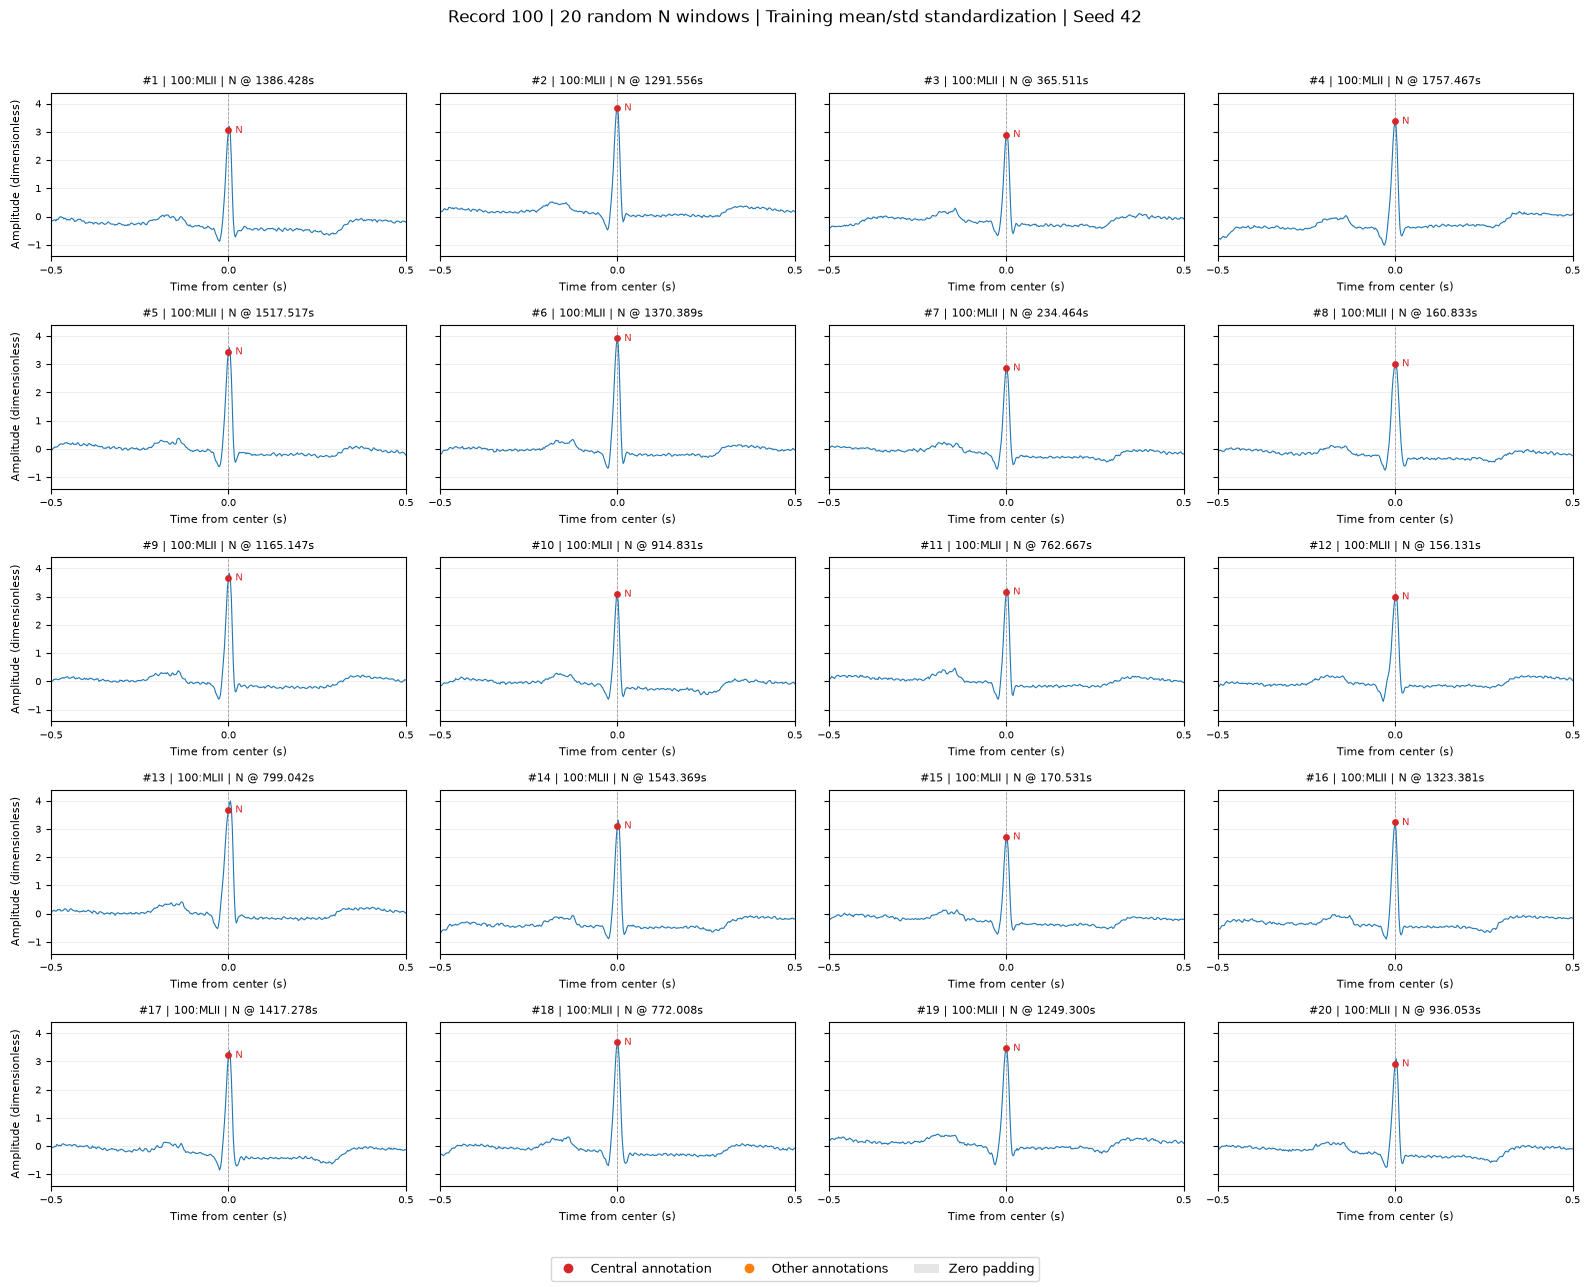

In [17]:
preprocessing_example_record = wfdb.rdrecord(str(project_root / "data/raw/mitdb-1.0.0/100"))
preprocessing_example_annotations = wfdb.rdann(str(project_root / "data/raw/mitdb-1.0.0/100"), "atr")
preprocessing_example_windows = [
    window for window in generate_ecg_windows(
        preprocessing_example_record, preprocessing_example_annotations, annotation_symbol="N", channel=0
    ) if window.is_complete
]
random_window_indices = np.random.default_rng(42).choice(len(preprocessing_example_windows), size=20, replace=False)
random_raw_windows = [preprocessing_example_windows[index] for index in random_window_indices]
preprocessed_windows_and_states = [
    preprocess_window(window, training_statistics, mode="standardize")
    for window in random_raw_windows
]
random_preprocessed_windows = [window for window, state in preprocessed_windows_and_states]
restored_windows = [inverse_preprocess_window(window, state) for window, state in preprocessed_windows_and_states]
inverse_max_abs_error = max(
    float(np.max(np.abs(restored.signal - original.signal)))
    for original, restored in zip(random_raw_windows, restored_windows)
)
print(f"Selected N annotation indices: {[window.annotation.annotation_index for window in random_raw_windows]}")
print(f"Maximum inverse error: {inverse_max_abs_error:.3e} {training_statistics.unit}")
fig, axes = plot_ecg_windows_grid(random_preprocessed_windows, ncols=4)
fig.suptitle("Record 100 | 20 random N windows | Training mean/std standardization | Seed 42", fontsize=12)
plt.show()

## Final dataset selection and preprocessing audit

Use channel 0 and keep **complete central-N windows in train**. Validation and test accept complete windows with every original central symbol except `+`. The `+` marker is never a window center and is ignored among neighbors. Full windows with other annotations remain eligible. Keep original central symbols in metadata; no binary target mapping is applied.

`dataset_preprocessing_mode` selects `none`, `center`, or `standardize` for all three splits. Reuse the training statistics above, refitted exclusively on the complete central-N windows remaining in train. `prepared_datasets[split].X` has shape `(accepted windows, 361)`; `metadata.iloc[i]` and `states[i]` describe row `X[i]`. Arrays and metadata are held in `prepared_datasets` in memory; rerun the preparation cell to recreate them.

The audit includes every original source entry, including excluded `+` markers for accounting. These markers never produce windows. `Result shape` describes the accepted subset of each central symbol. If both a non-N training center and incompleteness apply, the combined reason is reported once; reason counts therefore sum to rejected entries.

In [18]:
from scripts.datasets import prepare_window_datasets

dataset_preprocessing_mode = "standardize"
prepared_datasets, dataset_audit, dataset_rejection_reasons = prepare_window_datasets(
    raw_directory=project_root / "data/raw/mitdb-1.0.0",
    record_splits=preprocessing_splits,
    source_record_ids=record_ids,
    statistics=training_statistics,
    extract_window=extract_ecg_window,
    mode=dataset_preprocessing_mode,
)
dataset_summary = dataset_audit.groupby("split")[[
    "Source entries", "Accepted windows", "Rejected entries"
]].sum().reindex(["train", "validation", "test"])
dataset_summary["X shape"] = [prepared_datasets[split].X.shape for split in dataset_summary.index]
display(dataset_summary)
with pd.option_context("display.max_rows", None):
    display(dataset_audit)
    display(dataset_rejection_reasons)

,Source entries,Accepted windows,Rejected entries,X shape
split,,,,
train,71146,45443,25703,"(45443, 361)"
validation,19789,19502,287,"(19502, 361)"
test,21712,21593,119,"(21593, 361)"


Source entries  ...  Result shape
split      symbol                  ...              
train      !                  472  ...      (0, 361)
           "                  431  ...      (0, 361)
           +                  908  ...      (0, 361)
           /                 2922  ...      (0, 361)
           A                 2388  ...      (0, 361)
           E                  106  ...      (0, 361)
           F                  782  ...      (0, 361)
           J                   81  ...      (0, 361)
           L                 5583  ...      (0, 361)
           N                45467  ...  (45443, 361)
           Q                   31  ...      (0, 361)
           R                 5434  ...      (0, 361)
           S                    2  ...      (0, 361)
           V                 4548  ...      (0, 361)
           [                    6  ...      (0, 361)
           ]                    6  ...      (0, 361)
           a                  144  ...      (0, 361)
           e                   16  ...      (0, 361)
           f                  926  ...      (0, 361)
           j                  229  ...      (0, 361)
           x                   60  ...      (0, 361)
           |                  116  ...      (0, 361)
           ~                  488  ...      (0, 361)
validation !                    0  ...      (0, 361)
           "                    4  ...      (4, 361)
           +                  278  ...      (0, 361)
           /                 2078  ...   (2077, 361)
           A                   41  ...     (41, 361)
           E                    0  ...      (0, 361)
           F                    3  ...      (3, 361)
           J                    0  ...      (0, 361)
           L                    0  ...      (0, 361)
           N                13950  ...  (13942, 361)
           Q                    2  ...      (2, 361)
           R                 1825  ...   (1825, 361)
           S                    0  ...      (0, 361)
           V                 1393  ...   (1393, 361)
           [                    0  ...      (0, 361)
           ]                    0  ...      (0, 361)
           a                    6  ...      (6, 361)
           e                    0  ...      (0, 361)
           f                    0  ...      (0, 361)
           j                    0  ...      (0, 361)
           x                  133  ...    (133, 361)
           |                    7  ...      (7, 361)
           ~                   69  ...     (69, 361)
test       !                    0  ...      (0, 361)
           "                    2  ...      (2, 361)
           +                  105  ...      (0, 361)
           /                 2028  ...   (2026, 361)
           A                  117  ...    (117, 361)
           E                    0  ...      (0, 361)
           F                   18  ...     (18, 361)
           J                    2  ...      (2, 361)
           L                 2492  ...   (2490, 361)
           N                15635  ...  (15626, 361)
           Q                    0  ...      (0, 361)
           R                    0  ...      (0, 361)
           S                    0  ...      (0, 361)
           V                 1189  ...   (1188, 361)
           [                    0  ...      (0, 361)
           ]                    0  ...      (0, 361)
           a                    0  ...      (0, 361)
           e                    0  ...      (0, 361)
           f                   56  ...     (56, 361)
           j                    0  ...      (0, 361)
           x                    0  ...      (0, 361)
           |                    9  ...      (9, 361)
           ~                   59  ...     (59, 361)

[69 rows x 4 columns]

,split,symbol,reason,count
0,test,+,excluded_plus_marker,105
1,test,/,incomplete_window,2
2,test,L,incomplete_window,2
3,test,N,incomplete_window,9
4,test,V,incomplete_window,1
5,train,!,train_center_not_N,472
6,train,"""",train_center_not_N,431
7,train,+,excluded_plus_marker,908
8,train,/,train_center_not_N,2920
9,train,/,train_center_not_N;incomplete_window,2


### Trace one result row back to the source

Choose a split and a zero-based row. Metadata recovers the original record, subject, channel, and central annotation index/sample. Re-read that source window, invert preprocessing with the stored state, and check equality up to floating point rounding. Source interval stop positions are exclusive; the central annotation is at row position 180.

In [19]:
from dataclasses import replace

trace_split = "train"
trace_row_id = 0
trace_dataset = prepared_datasets[trace_split]
trace_metadata = trace_dataset.metadata.iloc[trace_row_id]
trace_source_path = project_root / "data/raw/mitdb-1.0.0" / trace_metadata["record_id"]
trace_source_record = wfdb.rdrecord(str(trace_source_path))
trace_source_annotations = wfdb.rdann(str(trace_source_path), "atr")
trace_source_window = extract_ecg_window(
    trace_source_record, trace_source_annotations,
    annotation_index=int(trace_metadata["annotation_index"]),
    channel=int(trace_metadata["channel"]),
)
trace_processed_window = replace(
    trace_source_window,
    signal=trace_dataset.X[trace_row_id].copy(),
    unit=trace_metadata["unit"],
)
trace_restored_window = inverse_preprocess_window(trace_processed_window, trace_dataset.states[trace_row_id])
np.testing.assert_allclose(trace_restored_window.signal, trace_source_window.signal, rtol=1e-12, atol=1e-12)
display(trace_metadata.to_frame("Value"))
print(f"Dataset row: {trace_split}[{trace_row_id}]")
print(f"Original annotation time: {trace_metadata['annotation_sample'] / trace_metadata['fs']:.6f} s")
print(f"Central annotation position in the row: {trace_source_window.center_index}")
print(f"Maximum source reconstruction error: {np.max(np.abs(trace_restored_window.signal - trace_source_window.signal)):.3e} mV")

Dataset row: train[0]
Original annotation time: 1.027778 s
Central annotation position in the row: 180
Maximum source reconstruction error: 1.110e-16 mV


,Value
row_id,0
record_id,100
subject_id,100
channel,0
channel_name,MLII
annotation_index,2
annotation_sample,370
annotation_symbol,N
fs,360.0
window_start_sample,190
